<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Tv         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None
               Tv       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000
Missing: {'Tv': 0, 'Radio': 0, 'Newspaper': 0, 'Sales': 0} | Duplicates: 0


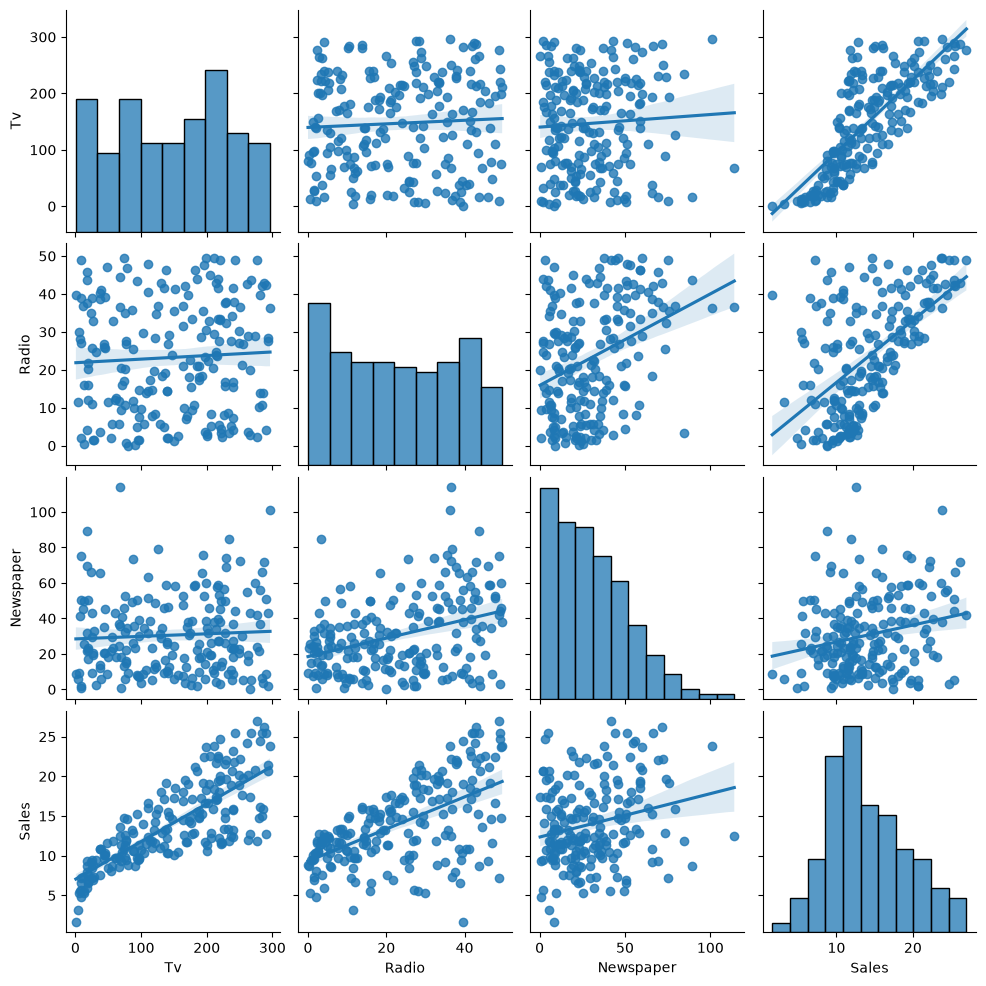

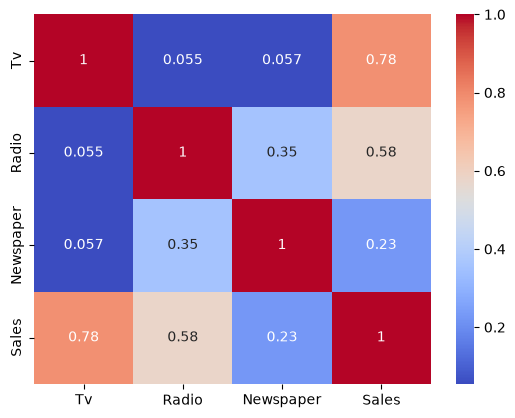

            Model    CV R2  Test R2      MAE     RMSE
    Poly(2)+Ridge 0.977239 0.986918 0.526172 0.642579
Gradient Boosting 0.969725 0.983127 0.618742 0.729782
    Random Forest 0.970118 0.982620 0.613900 0.740650
            Ridge 0.859490 0.899438 1.460766 1.781599
           Linear 0.859488 0.899438 1.460757 1.781600


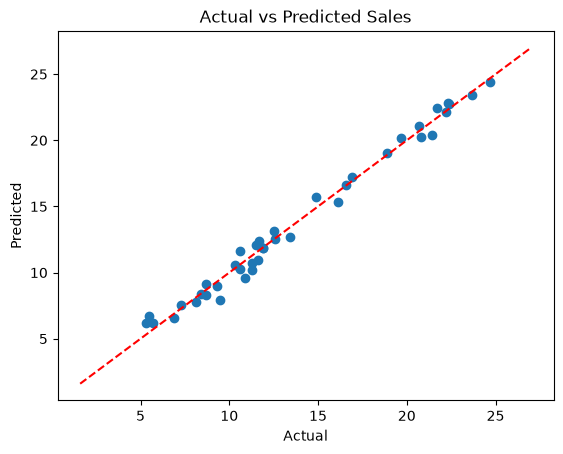


Sales change per +1 unit ad spend: {'Tv': np.float64(0.0458), 'Radio': np.float64(0.1885), 'Newspaper': np.float64(-0.001)}
+10% Tv spend -> sales change +0.620
+10% Radio spend -> sales change +0.444
+10% Newspaper spend -> sales change +0.014

Insights: TV and Radio drive sales; Newspaper has little/no effect.
Recommendation: shift budget from Newspaper to TV/Radio and track ROI per channel.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load and clean
df = pd.read_csv("Advertising.csv")
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")])
df.columns = [c.strip().title() for c in df.columns]
print(df.info()); print(df.describe())
print("Missing:", df.isna().sum().to_dict(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# EDA
sns.pairplot(df, kind="reg"); plt.show()
sns.heatmap(df.corr(), annot=True, cmap="coolwarm"); plt.show()

# Train/test split
X, y = df[["Tv", "Radio", "Newspaper"]], df["Sales"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Compare models
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Poly(2)+Ridge": make_pipeline(PolynomialFeatures(2), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows = []
for n, m in models.items():
    cv = cross_val_score(m, X_tr, y_tr, cv=5, scoring="r2").mean()
    m.fit(X_tr, y_tr); p = m.predict(X_te)
    rows.append([n, cv, r2_score(y_te, p), mean_absolute_error(y_te, p), np.sqrt(mean_squared_error(y_te, p))])
res = pd.DataFrame(rows, columns=["Model", "CV R2", "Test R2", "MAE", "RMSE"]).sort_values("Test R2", ascending=False)
print(res.to_string(index=False))

# Actual vs predicted (best model)
best = models[res.iloc[0]["Model"]]
plt.scatter(y_te, best.predict(X_te)); plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted Sales"); plt.show()

# Impact of advertising
lr = LinearRegression().fit(X, y)
print("\nSales change per +1 unit ad spend:", dict(zip(X.columns, lr.coef_.round(4))))
for ch in X.columns:
    base = X.mean().to_frame().T
    up = base.copy(); up[ch] *= 1.10
    print(f"+10% {ch} spend -> sales change {best.predict(up)[0] - best.predict(base)[0]:+.3f}")

print("""
Insights: TV and Radio drive sales; Newspaper has little/no effect.
Recommendation: shift budget from Newspaper to TV/Radio and track ROI per channel.""")